# Exercise 46 – Bead-spring chains: energy minimisation with autograd

**Week 8 · Automatic differentiation**

The positions of the beads are the parameters of a `nn.Module` whose forward
pass returns the potential energy. Minimising that energy with Adam finds the
equilibrium configuration. The two end beads are held fixed.

1. Three beads, springs with zero rest length: $E = \tfrac{k}{2}\sum d_i^2$.
2. Five beads, springs with rest length $d_0 = 1.5$:
   $E = \tfrac{k}{2}\sum (d_i - d_0)^2$.
3. The same chain with gravity acting on the free beads: $E \mathrel{+}= g\sum y_i$.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn

from comphy.clusters import plot_cluster
from comphy.plotting import setup_axes


class SpringChain(nn.Module):
    """Chain of beads connected by harmonic springs; the end beads are fixed."""

    def __init__(self, positions, k=1.0, rest_length=0.0, gravity=0.0):
        super().__init__()
        positions = torch.as_tensor(positions, dtype=torch.float32)
        self.k, self.rest_length, self.gravity = k, rest_length, gravity
        self.register_buffer("ends", positions[[0, -1]].clone())
        self.free = nn.Parameter(positions[1:-1].clone())

    @property
    def positions(self):
        return torch.cat([self.ends[:1], self.free, self.ends[1:]])

    def forward(self):
        bond_lengths = (self.positions[1:] - self.positions[:-1]).norm(dim=1)
        energy = 0.5 * self.k * ((bond_lengths - self.rest_length) ** 2).sum()
        return energy + self.gravity * self.free[:, 1].sum()


def relax(model, steps=5000, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        energy = model()
        energy.backward()
        optimizer.step()
    return model().item()


def before_and_after(start, model, xlim, ylim, titles):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    plot_cluster(axes[0], start, chain=True)
    plot_cluster(axes[1], model.positions.detach(), chain=True)
    for ax, title in zip(axes, titles):
        setup_axes(ax, xlim=xlim, ylim=ylim, title=title, zero_lines=False, equal=True)
    fig.tight_layout()
    plt.show()

## 1. Three beads, zero rest length
The middle bead ends up exactly halfway between the fixed ends.

Equilibrium energy: 4.000, middle bead at [[2. 0.]]


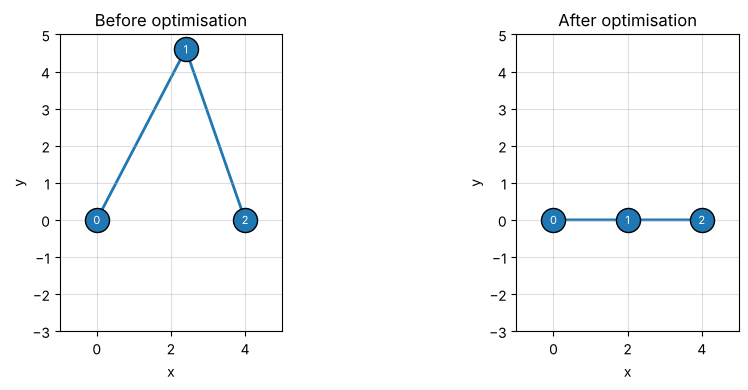

In [2]:
start = [[0, 0], [2.4, 4.6], [4, 0]]
chain = SpringChain(start, k=1)
energy = relax(chain, steps=2000)
print(f"Equilibrium energy: {energy:.3f}, middle bead at {chain.free.detach().numpy().round(3)}")
before_and_after(start, chain, (-1, 5), (-3, 5), ["Before optimisation", "After optimisation"])

## 2. Five beads, rest length 1.5

Equilibrium energy: 0.0000


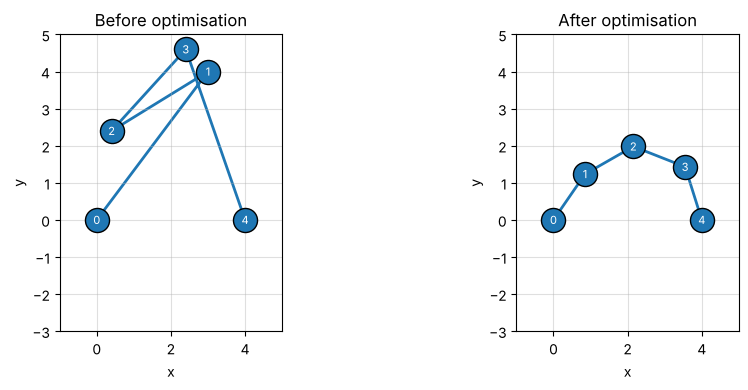

In [3]:
start = [[0, 0], [3, 4], [0.4, 2.4], [2.4, 4.6], [4, 0]]
chain = SpringChain(start, k=1, rest_length=1.5)
energy = relax(chain, steps=7000)
print(f"Equilibrium energy: {energy:.4f}")
before_and_after(start, chain, (-1, 5), (-3, 5), ["Before optimisation", "After optimisation"])

The chain (total rest length $4 \times 1.5 = 6$) is longer than the distance
between the ends (4), so it buckles and the energy can reach zero.

## 3. Adding gravity

Equilibrium energy: -75.843


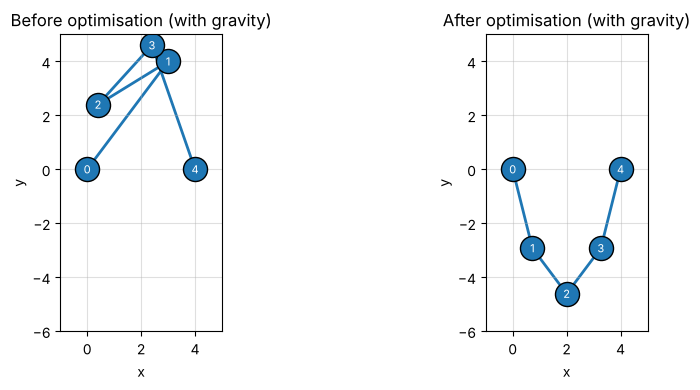

In [4]:
chain = SpringChain(start, k=10, rest_length=1.5, gravity=9.8)
energy = relax(chain, steps=5000, lr=0.005)
print(f"Equilibrium energy: {energy:.3f}")
before_and_after(start, chain, (-1, 5), (-6, 5),
                 ["Before optimisation (with gravity)", "After optimisation (with gravity)"])